# caneblu: a guided tour

This notebook shows, tests and implements every module of the `caneblu` package:

| Section | Module |
|---|---|
| 0. Setup | (shared helpers) |
| 1. Spectral indices | `composite_indices` |
| 2. Evalscripts | `evalscript_generator_utils` |
| 3. Geometry and squares | `geocoding` |
| 4. Rasters and features | `satellite_image_utils` |
| 5. Sentinel Hub client | `harvester` (offline parts) |
| 6. Open-Meteo | `open_meteo_api` (offline parts) |
| 7. Utilities | `utils` |
| 8. End-to-end pipeline | all of the above |
| 9. Test summary | checks every section |

Everything runs **offline by default**. Cells that call Sentinel Hub or Open-Meteo are behind the
`RUN_NETWORK` flag in the setup cell. To enable them, set `RUN_NETWORK = True` and provide credentials
(see the README, *Credentials*).

All files are written to a temporary directory, so the repository is not modified.

**Setup:** install the package in the environment that runs this notebook, from the repository root:

```bash
pip install -e .
pip install jupyter
jupyter notebook notebooks/caneblu_tour.ipynb
```

## 0. Setup

In [1]:
import os
import sys
import json
import shutil
import tempfile
import contextlib
import random
from unittest import mock

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import tifffile
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon, box

import caneblu
from caneblu import composite_indices as ci
from caneblu import evalscript_generator_utils as egu
from caneblu import geocoding as geo
from caneblu import satellite_image_utils as siu
from caneblu import utils
from caneblu import open_meteo_api as omapi
from caneblu import harvester as hv

# Set to True to call the real Sentinel Hub and Open-Meteo services (needs network and credentials)
RUN_NETWORK = False

# Scratch directory for everything this notebook writes
WORK = tempfile.mkdtemp(prefix="caneblu_tour_")

@contextlib.contextmanager
def in_dir(path):
    """Temporarily change the working directory (some functions write to ./data)."""
    old = os.getcwd()
    os.chdir(path)
    try:
        yield
    finally:
        os.chdir(old)

# Results of every check, collected in section 9
CHECKS = []

def check(name, condition):
    CHECKS.append((name, bool(condition)))
    return bool(condition)

print("caneblu version:", caneblu.__version__)
print("RUN_NETWORK:", RUN_NETWORK)
print("work dir:", WORK)

caneblu version: 0.1.0
RUN_NETWORK: False
work dir: /tmp/caneblu_tour_04fe2zhd


/tmp/claude-1000/-home-edoardo-devel-caneblu/6530555a-9250-4652-b40c-6841e6f34f79/scratchpad/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Spectral indices (`composite_indices`)

Every index takes an image of shape `(height, width, bands)` plus the **positions** of the bands it
needs. The band positions depend on the evalscript that produced the data (see the README band table).

Here we use the `fire_risk_bands_60m` layout: `0 B02, 1 B03, 2 B04 (red), 3 B08 (NIR), 4 B11 (SWIR1), 5 B12 (SWIR2)`.

NDVI   shape=(60, 60)  mean(veg)=+0.837  mean(soil)=+0.111  mean(water)=-0.428
NDWI   shape=(60, 60)  mean(veg)=-0.731  mean(soil)=-0.190  mean(water)=+0.599
MNDWI  shape=(60, 60)  mean(veg)=-0.481  mean(soil)=-0.277  mean(water)=+0.777
NBR    shape=(60, 60)  mean(veg)=+0.636  mean(soil)=+0.000  mean(water)=+0.332
NDMI   shape=(60, 60)  mean(veg)=+0.385  mean(soil)=-0.091  mean(water)=+0.332
NDSI   shape=(60, 60)  mean(veg)=+0.481  mean(soil)=+0.277  mean(water)=-0.777
MSI    shape=(60, 60)  mean(veg)=+0.444  mean(soil)=+1.200  mean(water)=+0.498


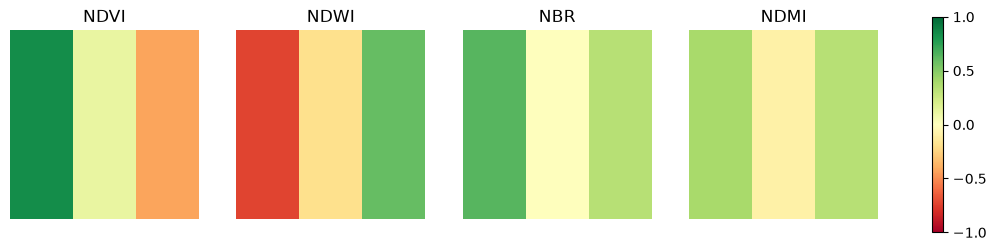

True

In [2]:
# A synthetic 60 x 60 scene: healthy vegetation on the left, bare soil in the middle, water on the right
H, W = 60, 60
scene = np.zeros((H, W, 6))
scene[:, :20] = [0.04, 0.07, 0.04, 0.45, 0.20, 0.10]   # vegetation
scene[:, 20:40] = [0.15, 0.17, 0.20, 0.25, 0.30, 0.25] # bare soil
scene[:, 40:] = [0.06, 0.08, 0.05, 0.02, 0.01, 0.01]   # water

idx = {
    "NDVI":  ci.NDVI(scene, i_red=2, i_nir=3),
    "NDWI":  ci.NDWI(scene, i_green=1, i_nir=3),
    "MNDWI": ci.MNDWI(scene, i_green=1, i_swir=4),
    "NBR":   ci.NBR(scene, i_swir=5, i_nir=3),
    "NDMI":  ci.NDMI(scene, i_swir=4, i_nir=3),
    "NDSI":  ci.NDSI(scene, i_vnir=1, i_swir=4),
    "MSI":   ci.MSI(scene, i_swir=4, i_nir=3),
}

for name, arr in idx.items():
    print(f"{name:6s} shape={arr.shape}  mean(veg)={arr[:, :20].mean():+.3f}  mean(soil)={arr[:, 20:40].mean():+.3f}  mean(water)={arr[:, 40:].mean():+.3f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, name in zip(axes, ["NDVI", "NDWI", "NBR", "NDMI"]):
    im = ax.imshow(idx[name], cmap="RdYlGn", vmin=-1, vmax=1)
    ax.set_title(name)
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

# Tests
check("NDVI is high on vegetation", idx["NDVI"][:, :20].mean() > 0.5)
check("NDVI is negative on water", idx["NDVI"][:, 40:].mean() < 0)
check("NDVI stays within [-1, 1]", np.all(np.abs(idx["NDVI"]) <= 1.0))
check("NDWI is positive on water", idx["NDWI"][:, 40:].mean() > 0)
check("NBR shape matches image", idx["NBR"].shape == (H, W))
check("MSI is SWIR/NIR (vegetation ~0.44)", abs(idx["MSI"][:, :20].mean() - 0.2 / 0.45) < 0.01)

### Burn severity with dNBR

Burn severity is the drop in NBR between a pre-fire and a post-fire scene. Here the vegetated area
burns, so its NBR collapses.

In [3]:
post = scene.copy()
post[:, :20] = [0.12, 0.10, 0.10, 0.12, 0.25, 0.30]   # burned vegetation

dnbr = ci.NBR(scene, i_swir=5, i_nir=3) - ci.NBR(post, i_swir=5, i_nir=3)
print("mean dNBR on burned area:", round(dnbr[:, :20].mean(), 3))
print("mean dNBR on untouched water:", round(dnbr[:, 40:].mean(), 3))

check("burned area has large dNBR", dnbr[:, :20].mean() > 0.44)
check("untouched water has dNBR near zero", abs(dnbr[:, 40:].mean()) < 0.05)

mean dNBR on burned area: 1.065
mean dNBR on untouched water: 0.0


True

## 2. Evalscripts (`evalscript_generator_utils`)

In [4]:
for name in ["all_bands_10m", "fire_risk_bands_60m", "bands_60m_rgb", "ndvi", "cloud_mask", "false_color"]:
    script = egu.get_evalscript(name)
    first_return = [line.strip() for line in script.splitlines() if line.strip().startswith("return")][0]
    print(f"{name:22s} -> {first_return}")

custom = egu.get_evalscript("custom_bands", bands=["B08", "B11"])
print("\ncustom_bands (B08, B11):")
print(custom)

try:
    egu.get_evalscript("does_not_exist")
except ValueError as err:
    print("Unknown name raises ValueError:", str(err)[:60], "...")

check("fire_risk script has 6 input bands", '"B02", "B03", "B04", "B08", "B11", "B12"' in egu.get_evalscript("fire_risk_bands_60m"))
check("custom script lists requested bands", 'bands: ["B08", "B11"]' in custom and "bands: 2" in custom)
raised = False
try:
    egu.get_evalscript("nope")
except ValueError:
    raised = True
check("unknown evalscript raises ValueError", raised)

all_bands_10m          -> return {
fire_risk_bands_60m    -> return {
bands_60m_rgb          -> return {
ndvi                   -> return {
cloud_mask             -> return {
false_color            -> return {

custom_bands (B08, B11):

            function setup() {
                return {
                    input: [{
                        bands: ["B08", "B11"]
                    }],
                    output: {
                        bands: 2
                    }
                };
            }

            function evaluatePixel(sample) {
                return [sample.B08, sample.B11];
            }
        
Unknown name raises ValueError: Unknown script: does_not_exist. Valid options are 'all_bands ...


True

## 3. Geometry, coordinates and squares (`geocoding`)

### 3.1 Boxes, polygons and coordinate order

In [5]:
area = geo.bbox_to_polygon((15.0, 37.0, 15.5, 37.5))   # (min_lon, min_lat, max_lon, max_lat)
print("bbox polygon area (deg^2):", area.area, "| valid:", area.is_valid)

# Swap (lat, lon) data into (lon, lat) shapes
swapped = geo.invert_polygon_latlon(Polygon([(37.0, 15.0), (37.5, 15.0), (37.5, 15.5), (37.0, 15.5)]))
print("after inversion bounds:", swapped.bounds)

# A point guaranteed to be inside a concave polygon
ushape = Polygon([(0, 0), (3, 0), (3, 3), (2, 3), (2, 1), (1, 1), (1, 3), (0, 3)])
px, py = geo.find_point_within_polygon(ushape)
print("representative point:", round(px, 2), round(py, 2), "inside:", ushape.contains(Point(px, py)))

check("bbox polygon has area 0.25", abs(area.area - 0.25) < 1e-12)
check("bbox polygon is valid", area.is_valid)
check("inversion swaps lon and lat", swapped.bounds == (15.0, 37.0, 15.5, 37.5))
check("representative point is inside", ushape.contains(Point(px, py)))

bbox polygon area (deg^2): 0.25 | valid: True
after inversion bounds: (15.0, 37.0, 15.5, 37.5)
representative point: 0.5 2.0 inside: True


True

### 3.2 Overlap of two shapes from different sources

In [6]:
official = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
digitised = Polygon([(0.2, 0.1), (10.1, 0.1), (10.1, 10.0), (0.2, 10.0)])
far_away = Polygon([(50, 50), (60, 50), (60, 60), (50, 60)])

print("overlap (default 75%):", geo.check_polygons_overlap(official, digitised))
print("overlap at 99%:", geo.check_polygons_overlap(official, digitised, overlap_min=0.99))
print("overlap with far-away shape:", geo.check_polygons_overlap(official, far_away))

check("similar shapes overlap", geo.check_polygons_overlap(official, digitised))
check("strict threshold rejects them", not geo.check_polygons_overlap(official, digitised, overlap_min=0.99))
check("distant shapes do not overlap", not geo.check_polygons_overlap(official, far_away))

overlap (default 75%): True
overlap at 99%: False
overlap with far-away shape: False


True

### 3.3 Random points and zones within a radius

In [7]:
random.seed(42)
ring = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
p = geo.resample_within_polygon(ring)
print("random point:", round(p.x, 3), round(p.y, 3), "inside:", ring.contains(p))

# Zones are measured in metres, so use a projected CRS (UTM 33N for Sicily)
zones = gpd.GeoDataFrame(
    {"name": ["near", "far"]},
    geometry=[
        box(15.00, 37.00, 15.01, 37.01),
        box(16.00, 38.00, 16.01, 38.01),
    ],
    crs="EPSG:4326",
).to_crs("EPSG:32633")

centre = zones.geometry.iloc[0].centroid
hits = geo.find_zones_within_radius(point=centre, radius=5000, geo_data=zones, crs="EPSG:32633")
print("zones within 5 km:", list(hits["name"]))

check("random point is inside the polygon", ring.contains(p))
check("radius search finds only the nearby zone", list(hits["name"]) == ["near"])

Found randomly resampled point:  2.557707193831535 0.10004302089066774
random point: 2.558 0.1 inside: True
Found 1 OMI zones within 5000 meters from the center.
zones within 5 km: ['near']


True

### 3.4 Splitting a province into squares

`generate_squares_for_province` needs a boundaries shapefile with a `SIGLA` column. The real province
file is on the author's machine, so this cell creates a small synthetic one. The squares are cached in `data/`.

Splitting polygon into squares...
[{'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 0, 'index_x': 0, 'index_y': 0}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 1, 'index_x': 0, 'index_y': 1}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 2, 'index_x': 0, 'index_y': 2}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 3, 'index_x': 0, 'index_y': 3}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 4, 'index_x': 0, 'index_y': 4}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 5, 'index_x': 0, 'index_y': 5}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 6, 'index_x': 0, 'index_y': 6}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index': 7, 'index_x': 0, 'index_y': 7}
 {'crs': 'UTM_33N', 'utm_zone': '33', 'utm_row': '', 'direction': 'N', 'index'

  0%|          | 0/130 [00:00<?, ?it/s]

 55%|█████▍    | 71/130 [00:00<00:00, 704.18it/s]

100%|██████████| 130/130 [00:00<00:00, 711.26it/s]

Saved to: data/CT_squares_5000.shp
squares for CT: 130 | cache returns the same number: True
CRS: epsg:4326


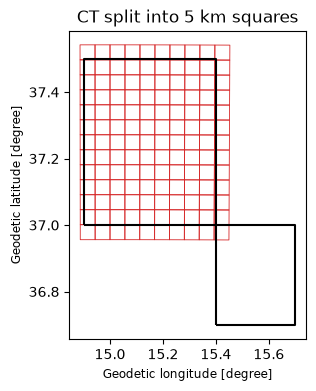

True

In [8]:
prov_dir = os.path.join(WORK, "geo")
os.makedirs(prov_dir, exist_ok=True)
prov_file = os.path.join(prov_dir, "provinces_wgs84.shp")
gpd.GeoDataFrame({"SIGLA": ["CT", "SR"]},
                 geometry=[box(14.9, 37.0, 15.4, 37.5), box(15.4, 36.7, 15.7, 37.0)],
                 crs="EPSG:4326").to_file(prov_file)

with in_dir(WORK):
    squares = geo.generate_squares_for_province(prov="CT", side=5000, geo_file=prov_file)
    cached = geo.generate_squares_for_province(prov="CT", side=5000, geo_file=prov_file)  # read from cache

print("squares for CT:", len(squares), "| cache returns the same number:", len(cached) == len(squares))
print("CRS:", squares.crs)

fig, ax = plt.subplots(figsize=(5, 4))
gpd.read_file(prov_file).boundary.plot(ax=ax, color="black")
squares.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=0.6)
ax.set_title("CT split into 5 km squares")
plt.show()

check("CT produced squares", len(squares) > 0)
check("second call reads the cache", len(cached) == len(squares))

## 4. Rasters, features and image utilities (`satellite_image_utils`)

### 4.1 Normalising, binning and masking

In [9]:
values = np.array([0.0, 2.0, 4.0, 8.0])
print("normalize:", siu.normalize(values))
print("bin_values (5 bins):", siu.bin_values(np.array([0.05, 0.3, 0.7, 0.99]), n_bins=5))
print("brighten (clipped to 0-255):", siu.brighten(np.array([100.0, 2000.0])))

dnbr_map = np.array([[0.1, 0.8], [0.5, 1.2]])
print("burned_mask (threshold 0.75):\n", siu.burned_mask(dnbr_map))

pred = np.array([1, 0, 1, 1])
true = np.array([1, 1, 1, 0])
print("compare_arrays -> (differences, %):", siu.compare_arrays(pred, true))

check("normalize maps to [0, 1]", siu.normalize(values).min() == 0 and siu.normalize(values).max() == 1)
check("bin_values returns 5 levels", set(np.unique(siu.bin_values(np.linspace(0, 1, 50), 5))) == {0.0, 0.25, 0.5, 0.75, 1.0})
check("burned_mask is binary", set(np.unique(siu.burned_mask(dnbr_map))) <= {0.0, 1.0})
check("compare_arrays counts differences", siu.compare_arrays(pred, true)[0] == 2)

normalize: [0.   0.25 0.5  1.  ]
bin_values (5 bins): [0.   0.25 0.75 1.  ]
brighten (clipped to 0-255): [ 13. 255.]
burned_mask (threshold 0.75):
 [[0. 1.]
 [0. 1.]]
compare_arrays -> (differences, %): (np.int64(2), np.float64(50.0))


True

### 4.2 Grayscale and colour mapping

gray_to_rgb: (6, 6, 3) uint8


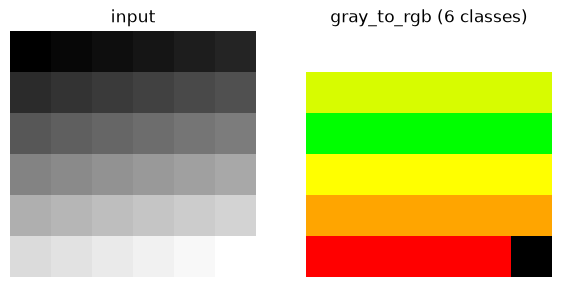

True

In [10]:
index_map = np.linspace(-0.2, 0.9, 36).reshape(6, 6)   # for example an NDVI map
rgb = siu.gray_to_rgb(index_map)
print("gray_to_rgb:", rgb.shape, rgb.dtype)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
axes[0].imshow(index_map, cmap="gray"); axes[0].set_title("input")
axes[1].imshow(rgb); axes[1].set_title("gray_to_rgb (6 classes)")
for a in axes: a.axis("off")
plt.show()

check("gray_to_rgb returns uint8 RGB", rgb.shape == (6, 6, 3) and rgb.dtype == np.uint8)

### 4.3 GeoTIFF write, read, merge and crop

In [11]:
tif_dir = os.path.join(WORK, "tiffs")
os.makedirs(tif_dir, exist_ok=True)

# A georeferenced 3-band raster over a 0.5 x 0.5 degree box
rng = np.random.default_rng(0)
raster = rng.uniform(0, 1, size=(40, 60, 3)).astype("float32")     # (H, W, bands)
roi = box(15.0, 37.0, 15.5, 37.5)
tif_path = os.path.join(tif_dir, "scene.tif")
siu.save_numpy_to_geotiff(raster, tif_path, roi=roi, crs="EPSG:4326")

with rasterio.open(tif_path) as src:
    back = src.read()                       # (bands, H, W)
    print("read back:", back.shape, "bounds:", tuple(round(b, 3) for b in src.bounds))

check("GeoTIFF round trip keeps the values", np.allclose(back.transpose(1, 2, 0), raster))

# Merge two adjacent tiles into a mosaic
left = np.full((20, 30, 3), 0.2, dtype="float32")
right = np.full((20, 30, 3), 0.8, dtype="float32")
siu.save_numpy_to_geotiff(left, os.path.join(tif_dir, "left.tif"), roi=box(15.0, 37.0, 15.5, 37.5), crs="EPSG:4326")
siu.save_numpy_to_geotiff(right, os.path.join(tif_dir, "right.tif"), roi=box(15.5, 37.0, 16.0, 37.5), crs="EPSG:4326")
mosaic_path = os.path.join(tif_dir, "mosaic.tif")
siu.merge_georeferenced_tiffs([os.path.join(tif_dir, "left.tif"), os.path.join(tif_dir, "right.tif")], mosaic_path)
with rasterio.open(mosaic_path) as src:
    print("mosaic size (W x H):", src.width, src.height, "| bounds:", tuple(round(b, 2) for b in src.bounds))
    mosaic = src.read()

check("mosaic spans both tiles", abs(mosaic.shape[2] - 60) <= 1)

# Crop a large raster with a polygon (the function keeps crops wider than 120 px)
big = rng.uniform(0, 1, size=(400, 400, 3)).astype("float32")
big_path = os.path.join(tif_dir, "big.tif")
siu.save_numpy_to_geotiff(big, big_path, roi=box(15.0, 37.0, 16.0, 38.0), crs="EPSG:4326")
crop_path = os.path.join(tif_dir, "crop.tif")
kept = siu.crop_tiff_with_polygon(big_path, crop_path, box(15.2, 37.2, 15.8, 37.8))
print("crop kept:", kept)
check("crop of a large area is saved", kept and os.path.exists(crop_path))

Array has been saved to GeoTIFF file: /tmp/caneblu_tour_04fe2zhd/tiffs/scene.tif
read back: (3, 40, 60) bounds: (15.0, 37.0, 15.5, 37.5)
Array has been saved to GeoTIFF file: /tmp/caneblu_tour_04fe2zhd/tiffs/left.tif
Array has been saved to GeoTIFF file: /tmp/caneblu_tour_04fe2zhd/tiffs/right.tif
Merged GeoTIFF saved at: /tmp/caneblu_tour_04fe2zhd/tiffs/mosaic.tif
mosaic size (W x H): 60 20 | bounds: (15.0, 37.0, 16.0, 37.5)
Array has been saved to GeoTIFF file: /tmp/caneblu_tour_04fe2zhd/tiffs/big.tif
crop kept: True


True

### 4.4 Preview images and RGB exports

In [12]:
# uint8 RGB raster -> PNG preview (tiff_to_png)
rgb8 = (rng.uniform(0, 1, size=(50, 50, 3)) * 255).astype("uint8")
rgb_tif = os.path.join(tif_dir, "rgb8.tif")
siu.save_numpy_to_geotiff(rgb8, rgb_tif, roi=box(15.0, 37.0, 15.1, 37.1), crs="EPSG:4326")
png_path = os.path.join(tif_dir, "preview.png")
img = siu.tiff_to_png(rgb_tif, png_path)
print("PNG written:", os.path.exists(png_path), "| size:", img.size)

# Folder of Sentinel-2 style TIFFs -> RGB images (create_rgb_imgs)
base = os.path.join(WORK, "s2")
src_dir = os.path.join(base, "CT_0001", "SENTINEL2_NO_CLOUDS")
os.makedirs(src_dir, exist_ok=True)
for day in ["2024-06-01", "2024-06-05"]:
    tifffile.imwrite(os.path.join(src_dir, f"{day}.tiff"),
                     rng.integers(0, 11000, size=(64, 64, 4), dtype=np.uint16))
rgb_list = siu.create_rgb_imgs(base_path=base, sub_paths=["CT_0001"], pxmax=11056)
print("RGB images created:", len(rgb_list), "| output folder:", os.listdir(os.path.join(base, "CT_0001", "RGB_DATA", "RGB")))

check("PNG preview is written", os.path.exists(png_path))
check("create_rgb_imgs writes one RGB per input", len(rgb_list) == 2 and rgb_list[0].shape == (64, 64, 3))

Array has been saved to GeoTIFF file: /tmp/caneblu_tour_04fe2zhd/tiffs/rgb8.tif
PNG written: True | size: (50, 50)
RGB images created: 2 | output folder: ['2024-06-01.tiff', '2024-06-05.tiff']


True

### 4.5 Feature tables and date sorting

In [13]:
shape = (10, 10)
ndvis = [rng.uniform(-0.2, 0.8, shape) for _ in range(3)]
ndmis = [rng.uniform(-0.2, 0.6, shape) for _ in range(3)]
rgbs = [rng.uniform(0, 255, shape) for _ in range(3)]
nbrs = [rng.uniform(-0.2, 0.7, shape) for _ in range(3)]

features = siu.create_features(ndvis, ndmis, rgbs, nbrs, n_dates=3)
print("features:", features.shape, "| columns:", list(features.columns)[:4], "...")

labels = (rng.uniform(size=shape) > 0.9).astype(float)
labelled = siu.create_features(ndvis, ndmis, rgbs, nbrs, dnbr_mask=labels, n_dates=3)
print("with label column:", labelled.columns[-1])

dates = ["2024-06-01", "2024-06-10", "2024-07-05", "2024-07-20"]
before, after = siu.sort_before_after(dates, "2024-07-01")
print("before the event (nearest first):", before)
print("after the event (nearest first):", after)

check("feature table has 4 features per date", features.shape == (100, 12))
check("labelled table ends with BURNED", labelled.columns[-1] == "BURNED")
check("sort_before_after splits the dates", before[0] == (2024, 6, 10) and after[0] == (2024, 7, 5))

features: (100, 12) | columns: ['NDVI_0', 'NDMI_0', 'RGB_0', 'NBR_0'] ...
with label column: BURNED
before the event (nearest first): [(2024, 6, 10), (2024, 6, 1)]
after the event (nearest first): [(2024, 7, 5), (2024, 7, 20)]


True

## 5. Sentinel Hub client (`harvester`)

### 5.1 Credentials and bounding boxes (offline)

Credentials are resolved in this order: arguments, then `SH_CLIENT_ID` / `SH_CLIENT_SECRET`, then the JSON file.
Here we test the first two without any network call.

In [14]:
client = hv.SentinelHub(client_id="demo-id", client_secret="demo-secret")
print("from arguments:", client.config.sh_client_id)

with mock.patch.dict(os.environ, {"SH_CLIENT_ID": "env-id", "SH_CLIENT_SECRET": "env-secret"}):
    from_env = hv.SentinelHub()
print("from environment:", from_env.config.sh_client_id)

check("arguments take precedence", client.config.sh_client_id == "demo-id")
check("environment is used next", from_env.config.sh_client_id == "env-id")

# Every accepted bounding-box form becomes the same sentinelhub BBox
from sentinelhub import BBox
forms = [
    (15.0, 37.0, 15.5, 37.5),
    Polygon([(15.0, 37.0), (15.5, 37.0), (15.5, 37.5), (15.0, 37.5)]),
    [(15.0, 37.0), (15.5, 37.0), (15.5, 37.5), (15.0, 37.5), (15.0, 37.0)],
    BBox((15.0, 37.0, 15.5, 37.5), crs="EPSG:4326"),
]
converted = [client._to_bbox(f) for f in forms]
print("all forms equal:", all(c == converted[0] for c in converted))

check("bounding box forms are equivalent", all(c == converted[0] for c in converted))

from arguments: demo-id
from environment: env-id
all forms equal: True


True

### 5.2 Evalscripts and the processing request (offline)

`request_box` builds a request and only calls the network when `get_data()` runs. Here we inspect the
evalscript that would be sent, without making the call.

In [15]:
print(client.get_raw_bands("ndvi").strip().splitlines()[0])
check("client exposes the evalscript for a data type", "function setup" in client.get_raw_bands("all_bands_10m"))

function setup() {


True

### 5.3 From downloaded arrays to fire-risk layers (offline)

`download_roi` returns a list of arrays, one per acquisition, in the layout of the chosen evalscript.
Here we fabricate three acquisitions with the `fire_risk_bands_60m` layout and feed them to the same
functions the pipeline uses.

In [16]:
acquisitions = [rng.uniform(0.02, 0.5, size=(40, 40, 6)) for _ in range(3)]

ndvis_f, ndmis_f, rgbs_gray_f, nbrs_f = hv.format_for_fire_risk(acquisitions, n_dates=3)
print("per-date layers:", len(ndvis_f), "| each", ndvis_f[0].shape)

features_f = siu.create_features(ndvis_f, ndmis_f, rgbs_gray_f, nbrs_f, n_dates=3)
print("feature table:", features_f.shape)

check("format_for_fire_risk returns 4 lists", len(ndvis_f) == len(ndmis_f) == len(rgbs_gray_f) == len(nbrs_f) == 3)
check("feature table has 1600 rows for a 40 x 40 tile", features_f.shape[0] == 1600)

per-date layers: 3 | each (40, 40)
feature table: (1600, 12)


True

### 5.4 Province download with a fake client (offline)

`download_province` splits a province into squares and calls `download_roi` for each square in the
requested range. Here a stand-in client records the calls, so the wiring can be tested without Sentinel Hub.

In [17]:
class FakeSentinelHub:
    """Stand-in for SentinelHub: records calls and returns synthetic arrays."""
    def __init__(self):
        self.calls = []

    def download_roi(self, bbox, **kwargs):
        self.calls.append({"bbox": tuple(round(b, 3) for b in bbox), **kwargs})
        arrays = [rng.uniform(0.02, 0.5, size=(20, 20, 6)) for _ in range(2)]
        files = [f"tmp/{kwargs['index']}_{i}.npy" for i in range(2)]
        return arrays, files

fake = FakeSentinelHub()
with in_dir(WORK):
    results = hv.download_province(
        prov="CT",
        side=5000,
        time_interval=("2025-06-15", "2025-06-30"),
        square_init=0,
        square_end=2,
        sh=fake,
        geo_file=prov_file,
        resolution=60,
        data_type="fire_risk_bands_60m",
        mosaic=True,
    )

print("squares downloaded:", sorted(results))
print("first call:", {k: fake.calls[0][k] for k in ["bbox", "index", "resolution", "mosaic", "data_type"]})

check("download_province returns one entry per square", sorted(results) == [0, 1])
check("each call receives the time interval", all(c["time_interval"] == ("2025-06-15", "2025-06-30") for c in fake.calls))
check("download options are forwarded", all(c["resolution"] == 60 and c["mosaic"] for c in fake.calls))

squares downloaded: [0, 1]
first call: {'bbox': (14.888, 36.956, 14.944, 37.001), 'index': 0, 'resolution': 60, 'mosaic': True, 'data_type': 'fire_risk_bands_60m'}


True

### 5.5 Command-line arguments (offline)

`parse_params` reads `sys.argv`. We pass a fake command line to show the parsing, including the
true/false flag for `--mosaic`.

In [18]:
with mock.patch.object(sys, "argv", ["harvester", "-p", "SR", "-m", "false", "-si", "2", "-se", "4", "-r", "60"]):
    params = hv.parse_params()
print({k: params[k] for k in ["prov", "mosaic", "square_init", "square_end", "resolution"]})

with mock.patch.object(sys, "argv", ["harvester", "-m", "True"]):
    mosaic_on = hv.parse_params()["mosaic"]
print("-m True ->", mosaic_on)

check("CLI parses the province", params["prov"] == "SR")
check("CLI parses -m false as False", params["mosaic"] is False)
check("CLI square indices are integers", params["square_init"] == 2 and params["square_end"] == 4)
check("CLI parses -m True as True", mosaic_on is True)

{'prov': 'SR', 'mosaic': False, 'square_init': 2, 'square_end': 4, 'resolution': 60}
-m True -> True


True

### 5.6 Real Sentinel Hub calls (network)

Runs only when `RUN_NETWORK = True`. It searches the catalogue and downloads one area.

In [19]:
if RUN_NETWORK:
    live = hv.SentinelHub()   # credentials from arguments, environment or the JSON file
    catalog = live.get_catalog(bbox=(15.0, 37.0, 15.5, 37.5), time_interval=("2024-06-01", "2024-06-30"), cloud_cover=10)
    print("acquisitions found:", len(catalog))
    with in_dir(WORK):
        arrays, files = live.download_roi(
            bbox=(15.0, 37.0, 15.5, 37.5),
            resolution=60,
            time_interval=("2024-06-01", "2024-06-30"),
            cloud_cover=10,
            data_type="all_bands_10m",
        )
    print("downloaded:", len(arrays), "arrays, shape", arrays[0].shape if arrays else None)
else:
    print("skipped: set RUN_NETWORK = True and provide credentials to run this cell")

skipped: set RUN_NETWORK = True and provide credentials to run this cell


## 6. Open-Meteo weather data (`open_meteo_api`)

### 6.1 Construction and dates (offline)

Creating an `OpenMeteoAPI` object does not call the network. The date window is `n_days` before `date_end`.

In [20]:
om = omapi.OpenMeteoAPI(lat=37.5, lon=15.1, date_end="2024-07-31", n_days=10)
print("latitude/longitude:", om.latitude(), om.longitude())
print("window:", om.date_start.format("YYYY-MM-DD"), "->", om.date_end.format("YYYY-MM-DD"))
om.info()

check("window starts 10 days before the end", om.date_start.format("YYYY-MM-DD") == "2024-07-21")
check("coordinates are kept", om.latitude() == 37.5 and om.longitude() == 15.1)

latitude/longitude: 37.5 15.1
window: 2024-07-21 -> 2024-07-31
At date:2024-07-31T00:00:00+00:00, lat: 37.5, lon: 15.1


True

### 6.2 Free and commercial endpoints (offline)

Requests are intercepted with a mock, so we can see which host and parameters each configuration uses.
With an API key the commercial `customer-` hosts are used, and the key is sent as a query parameter
(never inside the URL).

In [21]:
def capture_requests(om_obj):
    """Run one archive and one forecast call with requests.get mocked; return (url, params) pairs."""
    seen = []
    class FakeResponse:
        def json(self):
            return {"daily": {"time": []}, "hourly": {"time": []}}
    def fake_get(url, params=None, timeout=None):
        seen.append((url.split("?")[0], params))
        return FakeResponse()
    with mock.patch.object(omapi.requests, "get", side_effect=fake_get):
        om_obj.call_api(frequency="daily", call_type="archive", pause=0)
        om_obj.call_api(frequency="hourly", call_type="forecast", forecast_days=1)
    return seen

free_calls = capture_requests(omapi.OpenMeteoAPI(lat=37.5, lon=15.1, date_end="2024-07-31", n_days=10, api_key=None))
paid_calls = capture_requests(omapi.OpenMeteoAPI(lat=37.5, lon=15.1, date_end="2024-07-31", n_days=10, api_key="DEMO-KEY"))

print("free:")
for url, params in free_calls: print("  ", url, params)
print("with key:")
for url, params in paid_calls: print("  ", url, params)

check("free archive host", free_calls[0][0].startswith("https://archive-api."))
check("paid archive host and key", paid_calls[0][0].startswith("https://customer-archive-api.") and paid_calls[0][1] == {"apikey": "DEMO-KEY"})
check("key is never in the URL", all("apikey" not in url for url, _ in paid_calls))

free:
   https://archive-api.open-meteo.com/v1/archive None
   https://api.open-meteo.com/v1/forecast None
with key:
   https://customer-archive-api.open-meteo.com/v1/archive {'apikey': 'DEMO-KEY'}
   https://customer-api.open-meteo.com/v1/forecast {'apikey': 'DEMO-KEY'}


True

### 6.3 Live calls (network)

Runs only when `RUN_NETWORK = True`. The key is read from `OPEN_METEO_API_KEY` if it is set.

In [22]:
if RUN_NETWORK:
    live_om = omapi.OpenMeteoAPI(lat=37.5, lon=15.1, date_end="2024-07-31", n_days=10)
    daily = live_om.call_api(frequency="daily", call_type="archive")
    print("daily keys:", list(daily.keys()))
    hourly = live_om.history()
    print("hourly hours:", len(hourly["time"]))
else:
    print("skipped: set RUN_NETWORK = True to call Open-Meteo")

skipped: set RUN_NETWORK = True to call Open-Meteo


## 7. General utilities (`utils`)

In [23]:
print(utils.npy_filename("tmp/area_", 0, "2024-06-01", res=10))
print(utils.npy_mosaic_filename("tmp/area_", 0, "2024-06-01", res=10))

items = [
    {"id": "S2A_MSIL2A_20240601_T33SVB_123"},
    {"id": "S2B_MSIL2A_20240601_T33SVB_123"},   # same suffix: dropped
    {"id": "S2A_MSIL2A_20240605_T33SVB_456"},
]
unique_items = utils.remove_duplicates_from_list(items)
print("after de-duplication:", [i["id"][-3:] for i in unique_items])

geojson_path = os.path.join(WORK, "areas.geojson")
utils.dump_geojson({"type": "FeatureCollection", "features": []}, geojson_path)
print("read back type:", utils.read_json_file(geojson_path)["type"])
print("missing file returns:", utils.read_json_file(os.path.join(WORK, "missing.json")))
print("file older than 1 h?", utils.is_file_older_than(geojson_path, hours=1))

ts = utils.time_to_utc("2024-07-01")
print("time_to_utc:", ts, "-> back:", utils.utc_to_time(ts))
print("fix_time:", utils.fix_time(["2024-07-01T10:00:00Z", "2024-07-02T11:30:00Z"]))
print("modis_to_celsius(140000):", round(utils.modis_to_celsius(140000), 2))

check("npy filename follows the convention", utils.npy_filename("tmp/area_", 0, "2024-06-01", res=10) == "tmp/area__0000_2024-06-01_10.npy")
check("duplicates are removed", len(unique_items) == 2)
check("GeoJSON round trip", utils.read_json_file(geojson_path)["type"] == "FeatureCollection")
check("missing JSON returns None", utils.read_json_file(os.path.join(WORK, "missing.json")) is None)
check("fresh file is not old", utils.is_file_older_than(geojson_path, hours=1) is False)
check("time conversion round trip", utils.utc_to_time(ts).strftime("%Y-%m-%d") == "2024-07-01")
check("MODIS conversion", abs(utils.modis_to_celsius(140000) - 6.85) < 0.01)

tmp/area__0000_2024-06-01_10.npy
tmp/area__0000_2024-06-01_10_mosaic.npy
after de-duplication: ['123', '456']
read back type: FeatureCollection
Error: File not found at /tmp/caneblu_tour_04fe2zhd/missing.json!!
missing file returns: None
file older than 1 h? False
time_to_utc: 1719784800 -> back: 2024-07-01 00:00:00
fix_time: ['2024-07-01', '2024-07-02']
modis_to_celsius(140000): 6.85
Error: File not found at /tmp/caneblu_tour_04fe2zhd/missing.json!!


True

## 8. End-to-end: a fire-risk map from synthetic data

This ties the modules together with one 60 m tile of three dates. In a real run the arrays come from
`download_province` (section 5.6) and the boundaries from your own shapefile.

Pipeline:
1. arrays (one per date) → `format_for_fire_risk` (indices and grayscale)
2. indices → `create_features` (feature table)
3. change in NDVI between the first and last date → 5 risk classes with `bin_values`
4. write the risk map as a GeoTIFF, then read it back and plot it.

RISK_CLASS
0.00     738
0.25    2352
0.50     337
0.75     136
1.00      37
dtype: int64
Array has been saved to GeoTIFF file: /tmp/caneblu_tour_04fe2zhd/risk_map.tif


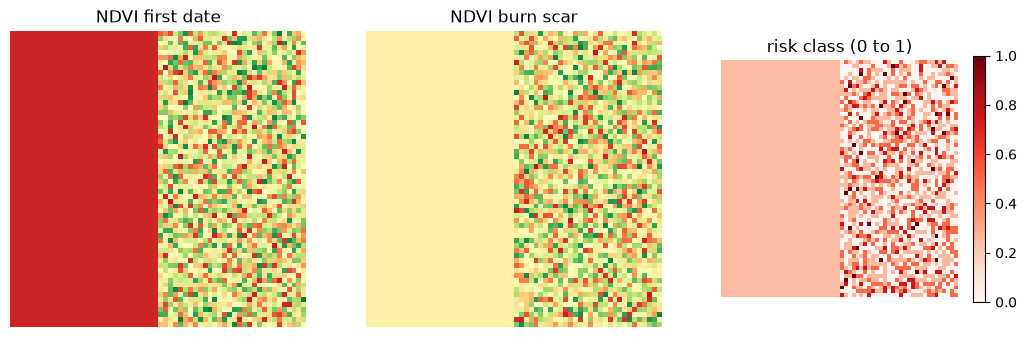

True

In [24]:
# 1. Three acquisitions of a 60 x 60 tile. The middle date has a burn scar on the left side.
dates_arrays = [rng.uniform(0.02, 0.5, size=(60, 60, 6)) for _ in range(3)]
dates_arrays[0][:, :30] = [0.04, 0.07, 0.04, 0.45, 0.20, 0.10]   # vegetated before the fire
dates_arrays[1][:, :30] = [0.12, 0.10, 0.10, 0.12, 0.25, 0.30]   # burn scar
dates_arrays[2][:, :30] = [0.10, 0.09, 0.08, 0.20, 0.25, 0.28]   # partial recovery

# 2. Indices and grayscale layers for the three dates
ndvis_e, ndmis_e, rgbs_e, nbrs_e = hv.format_for_fire_risk(dates_arrays, n_dates=3)

# 3. Feature table: one row per pixel
features_e = siu.create_features(ndvis_e, ndmis_e, rgbs_e, nbrs_e, n_dates=3)

# 4. Risk: how much NDVI changed between the first and last date, binned into 5 classes
change = np.abs(ndvis_e[-1] - ndvis_e[0])
risk = siu.bin_values(change.ravel() / max(change.max(), 1e-9), n_bins=5).reshape(change.shape)
features_e["RISK_CLASS"] = risk.ravel()
print(features_e.groupby("RISK_CLASS").size())

# 5. Write the risk map as a georeferenced GeoTIFF and read it back
risk_path = os.path.join(WORK, "risk_map.tif")
siu.save_numpy_to_geotiff(risk.astype("float32")[:, :, None], risk_path,
                          roi=box(15.0, 37.0, 15.5, 37.5), crs="EPSG:4326")
with rasterio.open(risk_path) as src:
    risk_back = src.read(1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(ndvis_e[0], cmap="RdYlGn", vmin=-1, vmax=1); axes[0].set_title("NDVI first date")
axes[1].imshow(ndvis_e[1], cmap="RdYlGn", vmin=-1, vmax=1); axes[1].set_title("NDVI burn scar")
im = axes[2].imshow(risk_back, cmap="Reds", vmin=0, vmax=1); axes[2].set_title("risk class (0 to 1)")
for a in axes: a.axis("off")
fig.colorbar(im, ax=axes[2], shrink=0.8)
plt.show()

check("feature table covers every pixel", features_e.shape[0] == 3600)
check("burn scar is classed higher than the rest", risk[:, :30].mean() > risk[:, 30:].mean())
check("risk map round-trips through GeoTIFF", np.allclose(risk_back, risk.astype("float32")))

## 9. Test summary

Every check made in the sections above, with its result. All checks should pass.

In [25]:
summary = pd.DataFrame(CHECKS, columns=["check", "passed"])
pd.set_option("display.max_colwidth", 80)
display(summary)

failed = summary[~summary["passed"]]
print(f"{len(summary) - len(failed)} / {len(summary)} checks passed")
assert failed.empty, f"Failed checks: {list(failed['check'])}"

,check,passed
0,NDVI is high on vegetation,True
1,NDVI is negative on water,True
2,"NDVI stays within [-1, 1]",True
3,NDWI is positive on water,True
4,NBR shape matches image,True
...,...,...
58,time conversion round trip,True
59,MODIS conversion,True
60,feature table covers every pixel,True
61,burn scar is classed higher than the rest,True


63 / 63 checks passed


## Cleaning up

The notebook wrote its files to a temporary directory. Remove it when you are done:

In [26]:
shutil.rmtree(WORK, ignore_errors=True)
print("removed", WORK)

removed /tmp/caneblu_tour_04fe2zhd
